In [1]:
# ---- Imports & Colab setup -------------------------------------------------
import os, sys, json, copy, time, random, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

IN_COLAB = "google.colab" in sys.modules
DRIVE_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/ColabData")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FROZEN_DIR = DRIVE_ROOT / "frozen"             # READ-ONLY: never written to
    OUT_DIR    = DRIVE_ROOT / "contrastive_outputs"            # all our outputs go here instead
else:
    FROZEN_DIR = Path("frozen")                    # local fallback (not Colab)
    OUT_DIR    = Path("contrastive_outputs")

REQUIRED = ["train_final.parquet", "test_final.parquet", "feature_cols_final.json"]

# If the frozen files are not on Drive, let the user upload them manually.
if not all((FROZEN_DIR / f).exists() for f in REQUIRED):
    if IN_COLAB:
        from google.colab import files
        print("Frozen files not found on Drive -> please upload:", REQUIRED)
        uploaded = files.upload()
        FROZEN_DIR = Path("/content/frozen_uploaded")
        FROZEN_DIR.mkdir(exist_ok=True)
        for name, content in uploaded.items():
            (FROZEN_DIR / name).write_bytes(content)
    missing = [f for f in REQUIRED if not (FROZEN_DIR / f).exists()]
    assert not missing, f"Missing frozen files: {missing}"

OUT_DIR.mkdir(parents=True, exist_ok=True)

# Fingerprint the frozen files NOW; we re-check at the very end of the notebook.
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

FROZEN_HASHES = {f: sha256(FROZEN_DIR / f) for f in REQUIRED}
print("Frozen data folder :", FROZEN_DIR)
print("Outputs folder     :", OUT_DIR)
for f, h in FROZEN_HASHES.items():
    print(f"  {f:28s} sha256 = {h[:16]}...")

Mounted at /content/drive
Frozen data folder : /content/drive/MyDrive/Colab Notebooks/ColabData/frozen
Outputs folder     : /content/drive/MyDrive/Colab Notebooks/ColabData/contrastive_outputs
  train_final.parquet          sha256 = 92df5884e56c6142...
  test_final.parquet           sha256 = 1d0ce78ec4e29a8b...
  feature_cols_final.json      sha256 = 9f512eb9baa59024...


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

def set_seed(seed: int):
    """Make runs reproducible (same numbers every time we re-run)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
if device.type == "cpu":
    print("Tip: Runtime > Change runtime type > T4 GPU makes this notebook much faster.")

PyTorch: 2.11.0+cu130 | device: cuda


## 1. Load the frozen data (read-only)

* `train_final.parquet` – 24 subjects, 19 501 epochs
* `test_final.parquet`  – 7 *different* subjects, 6 007 epochs
* `feature_cols_final.json` – the 12 features the team agreed on

These features were engineered in `project1.ipynb`: raw movement (`acc_mean`, `acc_std`), 5-epoch rolling statistics of heart rate and movement, epoch-to-epoch changes (`hr_delta`, `acc_delta`), per-subject z-scores (so a person's resting HR doesn't dominate), step bursts and the relative position in the night.

In [3]:
train_df = pd.read_parquet(FROZEN_DIR / "train_final.parquet")
test_df  = pd.read_parquet(FROZEN_DIR / "test_final.parquet")
with open(FROZEN_DIR / "feature_cols_final.json") as fh:
    feature_cols = json.load(fh)

print("train_final:", train_df.shape, "| subjects:", train_df["subject"].nunique())
print("test_final :", test_df.shape,  "| subjects:", test_df["subject"].nunique())
print(f"\n{len(feature_cols)} frozen features:")
for c in feature_cols:
    print("  -", c)

# ---- sanity checks on the frozen data -------------------------------------
assert len(feature_cols) == 12
assert set(feature_cols) <= set(train_df.columns) and set(feature_cols) <= set(test_df.columns)
assert np.isfinite(train_df[feature_cols].to_numpy()).all(), "NaN/inf in train features"
assert np.isfinite(test_df[feature_cols].to_numpy()).all(),  "NaN/inf in test features"
overlap = set(train_df["subject"]) & set(test_df["subject"])
assert not overlap, f"Subjects present in both train and test: {overlap}"
print("\nOK: features finite, and train/test subjects are disjoint.")

train_final: (19501, 24) | subjects: 24
test_final : (6007, 24) | subjects: 7

12 frozen features:
  - acc_mean
  - acc_std
  - hr_mean_clipped_roll5_mean
  - hr_mean_clipped_roll5_std
  - acc_mean_roll5_mean
  - acc_mean_roll5_std
  - hr_delta
  - acc_delta
  - hr_mean_clipped_subj_z
  - acc_mean_subj_z
  - steps_roll5_sum
  - night_position

OK: features finite, and train/test subjects are disjoint.


### Labels

The dataset has a numeric `stage` column and a text `stage_label` column. In the raw data **stage 3 and stage 4 are both labelled `N3`** (deep sleep, merged in the preprocessing notebook), so there are 6 numeric codes but only **5 classes**. We therefore build our target from `stage_label` — not from `stage` — to avoid accidentally creating a 6th class.

In [4]:
LABELS = ["Wake", "N1", "N2", "N3", "REM"]
N_CLASSES = len(LABELS)
label_to_id = {name: i for i, name in enumerate(LABELS)}

# .assign() returns a new DataFrame; the parquet files on disk are untouched.
train_df = train_df.assign(label=train_df["stage_label"].map(label_to_id))
test_df  = test_df.assign(label=test_df["stage_label"].map(label_to_id))
assert train_df["label"].notna().all() and test_df["label"].notna().all()

print("Raw stage codes vs. merged label (train):")
print(pd.crosstab(train_df["stage"], train_df["stage_label"]), "\n")

dist = pd.DataFrame({
    "train_epochs": train_df["stage_label"].value_counts().reindex(LABELS),
    "train_%": (train_df["stage_label"].value_counts(normalize=True).reindex(LABELS) * 100).round(1),
    "test_epochs": test_df["stage_label"].value_counts().reindex(LABELS),
    "test_%": (test_df["stage_label"].value_counts(normalize=True).reindex(LABELS) * 100).round(1),
})
dist

Raw stage codes vs. merged label (train):
stage_label    N1    N2    N3   REM  Wake
stage                                    
0               0     0     0     0  1606
1            1370     0     0     0     0
2               0  9720     0     0     0
3               0     0  2371     0     0
4               0     0   190     0     0
5               0     0     0  4244     0 



,train_epochs,train_%,test_epochs,test_%
stage_label,,,,
Wake,1606,8.2,562,9.4
N1,1370,7.0,392,6.5
N2,9720,49.8,2768,46.1
N3,2561,13.1,984,16.4
REM,4244,21.8,1301,21.7


**Observation – strong class imbalance.** N2 is about half of all epochs while N1 is only ~7 %. A model that always says "N2" would get ~46 % accuracy on the test subjects but be useless. That is why we report **macro-F1**, balanced accuracy and Cohen's kappa next to accuracy, and use (dampened) **class-weighted** cross-entropy. Note the trade-off: the more we favour rare stages, the lower the plain accuracy.

## 2. Subject-based split: train / validation / test

Neighbouring epochs of the same person are almost copies of each other (and our rolling features overlap on purpose). If we split *epochs* randomly, the model would be tested on epochs whose near-twins it trained on — a classic leak. So we split **by subject**:

```
24 training subjects ──► 19 "fit" subjects   (learn weights)
                    └──► 5 validation subjects (pick epochs / early stopping)
 7 test subjects ────────► touched only for the final report
```
`GroupShuffleSplit` with `groups=subject` guarantees whole subjects go to one side. We keep the same seed and 80/20 ratio as the earlier draft so results stay comparable.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
fit_idx, val_idx = next(gss.split(train_df, groups=train_df["subject"]))

fit_df = train_df.iloc[fit_idx].reset_index(drop=True)   # used to learn weights
val_df = train_df.iloc[val_idx].reset_index(drop=True)   # used for model selection
test_df = test_df.reset_index(drop=True)                 # final report only

S_fit, S_val, S_test = (set(d["subject"]) for d in (fit_df, val_df, test_df))
assert not (S_fit & S_val) and not (S_fit & S_test) and not (S_val & S_test), "Subject leakage!"

print(f"fit : {len(S_fit):2d} subjects, {len(fit_df):6d} epochs")
print(f"val : {len(S_val):2d} subjects, {len(val_df):6d} epochs -> {sorted(S_val)}")
print(f"test: {len(S_test):2d} subjects, {len(test_df):6d} epochs -> {sorted(S_test)}")
print("\nClass share (%) per split:")
pd.DataFrame({n: (d["stage_label"].value_counts(normalize=True).reindex(LABELS) * 100).round(1)
              for n, d in [("fit", fit_df), ("val", val_df), ("test", test_df)]})

fit : 19 subjects,  15323 epochs
val :  5 subjects,   4178 epochs -> ['1066528', '4314139', '5132496', '781756', '8173033']
test:  7 subjects,   6007 epochs -> ['3997827', '4018081', '5498603', '6220552', '8258170', '8692923', '9618981']

Class share (%) per split:


,fit,val,test
stage_label,,,
Wake,7.9,9.3,9.4
N1,5.8,11.4,6.5
N2,50.9,45.8,46.1
N3,13.3,12.5,16.4
REM,22.0,20.9,21.7


## 3. Scaling, class weights and data loaders

The frozen features are already roughly standardised (mean 0, std 1 over all 24 training subjects). That statistic includes our validation subjects, so to be strict we **re-fit a `StandardScaler` on the 19 fit subjects only** and apply it to validation and test. Applying a second linear rescaling is harmless; it just guarantees that no validation/test information shapes the preprocessing.

**Class weights.** Full "balanced" weights `N / (K · n_c)` make a mistake on a rare stage (N1) cost ~9× more than one on N2. That raises macro-F1 but **pulls overall accuracy down** (the model over-predicts rare stages). We use **square-root-dampened weights** `(N / (K · n_c))^0.5` as a compromise: rare stages still count more, but N2 is not sacrificed. Set `CLASS_WEIGHT_POWER = 1.0` for fully balanced weights or `0.0` for none. Weights are computed from the fit subjects only.

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(fit_df[feature_cols].to_numpy())          # fit ONLY on fit subjects

def prep(df):
    X = scaler.transform(df[feature_cols].to_numpy()).astype(np.float32)
    y = df["label"].to_numpy().astype(np.int64)
    return X, y

X_fit, y_fit   = prep(fit_df)
X_val, y_val   = prep(val_df)
X_test, y_test = prep(test_df)

X_fit_t,  y_fit_t  = torch.from_numpy(X_fit),  torch.from_numpy(y_fit)
X_val_t,  X_test_t = torch.from_numpy(X_val),  torch.from_numpy(X_test)

class_counts  = np.bincount(y_fit, minlength=N_CLASSES)
CLASS_WEIGHT_POWER = 0.5          # 1.0 = fully balanced, 0.5 = square-root dampened (default), 0.0 = no weighting
class_weights = torch.tensor((len(y_fit) / (N_CLASSES * class_counts)) ** CLASS_WEIGHT_POWER, dtype=torch.float32, device=device)
print("Class weights (from fit subjects):", dict(zip(LABELS, class_weights.cpu().numpy().round(2))))

BATCH_SIZE = 256   # large batches matter for contrastive learning: more positives & negatives per step

def make_train_loader(seed):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(TensorDataset(X_fit_t, y_fit_t), batch_size=BATCH_SIZE,
                      shuffle=True, drop_last=True, generator=g)

train_loader = make_train_loader(SEED)
xb, yb = next(iter(train_loader))
print("One batch:", tuple(xb.shape), tuple(yb.shape), "| classes in batch:", torch.bincount(yb, minlength=5).tolist())

Class weights (from fit subjects): {'Wake': np.float32(1.59), 'N1': np.float32(1.85), 'N2': np.float32(0.63), 'N3': np.float32(1.23), 'REM': np.float32(0.95)}
One batch: (256, 12) (256,) | classes in batch: [28, 11, 130, 38, 49]


## 4. The Supervised Contrastive (SupCon) loss

**Plain cross-entropy** looks at one sample at a time and asks "did you predict the right label?".
**SupCon** looks at *pairs*: take an *anchor* epoch $i$; every other epoch in the batch with the **same stage** is a **positive**, all others are **negatives**. The loss pulls positives together and pushes negatives away on the unit sphere:

$$
\mathcal{L}_{SupCon}=\sum_{i}\frac{-1}{|P(i)|}\sum_{p\in P(i)}\log\frac{\exp(z_i\cdot z_p/\tau)}{\sum_{a\ne i}\exp(z_i\cdot z_a/\tau)}
$$

* $z$ = L2-normalised embedding, so $z_i\cdot z_p$ is the **cosine similarity**.
* $P(i)$ = other samples in the batch with the same label as $i$.
* $\tau$ (**temperature**, 0.1 here) controls how sharply the loss focuses on the hardest negatives.

**Two noisy "views".** In images, SupCon uses two augmentations of each picture. For tabular sensor data we create two views by adding a little Gaussian noise (σ = 0.05 on standardised features). Benefits: every anchor always has at least one positive (its own twin) even for rare stages like N1, and the encoder becomes slightly robust to sensor noise.

**Projection head.** The loss is applied to the output of a small *projection head* sitting on top of the encoder. After pre-training we throw the projection head away and use the encoder output instead — the standard SupCon recipe, which keeps the representation more general.

In [7]:
class SupConLoss(nn.Module):
    """Supervised contrastive loss (Khosla et al., 2020)."""
    def __init__(self, temperature: float = 0.1):
        super().__init__()
        self.t = temperature

    def forward(self, z, labels):
        z = F.normalize(z, dim=1)                              # unit vectors -> dot product = cosine similarity
        sim = (z @ z.T) / self.t                               # [n, n] similarity of every pair
        n = z.size(0)
        self_mask = torch.eye(n, dtype=torch.bool, device=z.device)
        pos_mask = (labels[:, None] == labels[None, :]) & ~self_mask   # same stage, not itself

        sim = sim.masked_fill(self_mask, -1e9)                 # an anchor is never compared with itself
        log_prob = sim - torch.logsumexp(sim, dim=1, keepdim=True)     # log softmax over the other samples

        pos_mask = pos_mask.float()
        pos_count = pos_mask.sum(1)
        mean_log_prob_pos = (log_prob * pos_mask).sum(1) / pos_count.clamp(min=1)
        valid = pos_count > 0                                  # anchors that have >= 1 positive
        return -mean_log_prob_pos[valid].mean()

# ---- sanity test: random embeddings must give a HIGHER loss than well-clustered ones
crit = SupConLoss(0.1)
yb_test = y_fit_t[:256]
z_random  = torch.randn(256, 32)
centres   = torch.randn(N_CLASSES, 32)
z_cluster = centres[yb_test] + 0.05 * torch.randn(256, 32)     # same-stage points sit together
print(f"Loss with random embeddings   : {crit(z_random,  yb_test).item():.3f}")
print(f"Loss with clustered embeddings: {crit(z_cluster, yb_test).item():.3f}   (should be clearly lower)")

Loss with random embeddings   : 6.982
Loss with clustered embeddings: 4.147   (should be clearly lower)


## 5. Model architecture

```
12 features ──► ENCODER (12→128→64, BatchNorm+ReLU) ──► 64-d representation ─┬─► projection head (64→64→32)  ← used ONLY for the SupCon loss
                                                                              └─► classification head (64→5)  ← used for Stage 2
```
* The **encoder** is deliberately small: 12 tabular features do not need a deep network, and a small model is easier to explain.
* The **baseline MLP** will be *exactly* `encoder + classification head` with random weights, so any difference to the contrastive model comes from *how it was trained*, not from its size.

In [8]:
REP_DIM, PROJ_DIM = 64, 32

class Encoder(nn.Module):
    def __init__(self, in_dim, hidden=128, out_dim=REP_DIM, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, out_dim), nn.BatchNorm1d(out_dim), nn.ReLU(),
        )
    def forward(self, x):
        return self.net(x)

class ProjectionHead(nn.Module):
    def __init__(self, in_dim=REP_DIM, out_dim=PROJ_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, in_dim), nn.ReLU(), nn.Linear(in_dim, out_dim))
    def forward(self, h):
        return self.net(h)

class SleepClassifier(nn.Module):
    """encoder + linear classification head."""
    def __init__(self, encoder, rep_dim=REP_DIM, n_classes=N_CLASSES):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Linear(rep_dim, n_classes)
    def forward(self, x):
        return self.head(self.encoder(x))

def make_encoder():
    return Encoder(in_dim=len(feature_cols)).to(device)

encoder = make_encoder()
proj_head = ProjectionHead().to(device)
encoder_untrained = copy.deepcopy(encoder)       # kept for the "before training" plots in section 7

print(encoder)
print("Encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Encoder(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
  )
)
Encoder parameters: 10304


## 6. Stage 1 — contrastive pre-training

For each batch we build two noisy views, push both through encoder → projection head, and apply `SupConLoss` to the 2×256 embeddings (labels repeated). **Labels are used** (that is what "supervised" contrastive means), but no classifier exists yet.

**How do we know pre-training is working?** The SupCon loss on the training set tells us it is *optimising*, but not whether the embeddings *generalise to new people*. So every 5 epochs we also run a quick **k-nearest-neighbour check**: fit kNN on the fit-subject embeddings and measure macro-F1 on the **validation subjects**. We keep the encoder weights from the best check.

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, cohen_kappa_score,
                             classification_report, ConfusionMatrixDisplay)

@torch.no_grad()
def get_embeddings(enc, X_t, bs=2048):
    enc.eval()
    return torch.cat([enc(X_t[i:i + bs].to(device)).cpu() for i in range(0, len(X_t), bs)]).numpy()

def l2norm(a):
    return a / np.clip(np.linalg.norm(a, axis=1, keepdims=True), 1e-8, None)

def knn_val_f1(enc, k=15):
    """Macro-F1 of a kNN classifier in embedding space: fit on fit-subjects, scored on val-subjects."""
    z_fit, z_val = l2norm(get_embeddings(enc, X_fit_t)), l2norm(get_embeddings(enc, X_val_t))
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(z_fit, y_fit)
    return f1_score(y_val, knn.predict(z_val), average="macro")

PRETRAIN_EPOCHS = 60
TEMPERATURE     = 0.1
NOISE_STD       = 0.05
PRETRAIN_LR     = 1e-3

def pretrain_supcon(enc, proj, loader, epochs=PRETRAIN_EPOCHS, lr=PRETRAIN_LR,
                    temperature=TEMPERATURE, noise=NOISE_STD, eval_every=5, verbose=True):
    params = list(enc.parameters()) + list(proj.parameters())
    opt = torch.optim.Adam(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = SupConLoss(temperature)
    hist = {"loss": [], "knn_epoch": [], "knn_f1": []}
    best_f1, best_state = -1.0, None

    for ep in range(1, epochs + 1):
        enc.train(); proj.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            v1 = xb + noise * torch.randn_like(xb)             # view 1
            v2 = xb + noise * torch.randn_like(xb)             # view 2
            z = proj(enc(torch.cat([v1, v2])))                 # [2B, 32]
            loss = crit(z, torch.cat([yb, yb]))
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(xb); n += len(xb)
        sched.step()
        hist["loss"].append(total / n)

        if ep % eval_every == 0 or ep == epochs:
            f1 = knn_val_f1(enc)
            hist["knn_epoch"].append(ep); hist["knn_f1"].append(f1)
            if f1 > best_f1:
                best_f1, best_state = f1, copy.deepcopy(enc.state_dict())
            if verbose:
                print(f"epoch {ep:3d}/{epochs} | SupCon loss {hist['loss'][-1]:.4f} | val kNN macro-F1 {f1:.4f}")

    enc.load_state_dict(best_state)                            # restore the best encoder
    hist["best_knn_f1"] = best_f1
    return hist

epoch   5/60 | SupCon loss 6.0766 | val kNN macro-F1 0.3857
epoch  10/60 | SupCon loss 6.0085 | val kNN macro-F1 0.3691
epoch  15/60 | SupCon loss 5.9489 | val kNN macro-F1 0.3513
epoch  20/60 | SupCon loss 5.9105 | val kNN macro-F1 0.3484
epoch  25/60 | SupCon loss 5.8837 | val kNN macro-F1 0.3503
epoch  30/60 | SupCon loss 5.8608 | val kNN macro-F1 0.3555
epoch  35/60 | SupCon loss 5.8379 | val kNN macro-F1 0.3547
epoch  40/60 | SupCon loss 5.8240 | val kNN macro-F1 0.3523
epoch  45/60 | SupCon loss 5.8143 | val kNN macro-F1 0.3528
epoch  50/60 | SupCon loss 5.8032 | val kNN macro-F1 0.3553
epoch  55/60 | SupCon loss 5.8004 | val kNN macro-F1 0.3529
epoch  60/60 | SupCon loss 5.7968 | val kNN macro-F1 0.3524

Best validation kNN macro-F1: 0.3857  (35s)


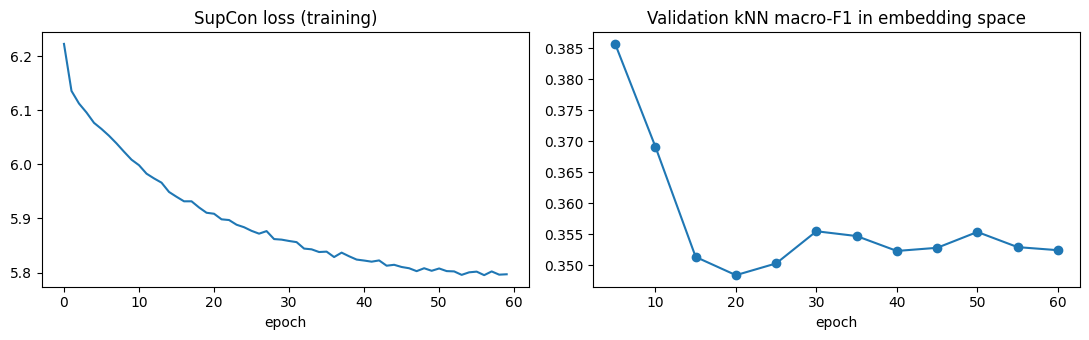

In [10]:
t0 = time.time()
pretrain_hist = pretrain_supcon(encoder, proj_head, train_loader)
print(f"\nBest validation kNN macro-F1: {pretrain_hist['best_knn_f1']:.4f}  ({time.time() - t0:.0f}s)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(pretrain_hist["loss"]);                       ax[0].set(title="SupCon loss (training)", xlabel="epoch")
ax[1].plot(pretrain_hist["knn_epoch"], pretrain_hist["knn_f1"], "o-"); ax[1].set(title="Validation kNN macro-F1 in embedding space", xlabel="epoch")
plt.tight_layout(); plt.show()

## 7. What did the encoder learn? (embedding visualisation)

t-SNE squashes high-dimensional points into 2-D so we can look at them. We plot **validation-subject** epochs (people the encoder never trained on), coloured by true stage, for (a) the raw standardised features, (b) the *untrained* encoder, (c) the *contrastive-pretrained* encoder.

Read these plots with care: t-SNE is only a visual aid. N2 dominates the picture, and heart-rate/movement cannot perfectly separate N1 from Wake or N2 — some overlap is expected and honest.

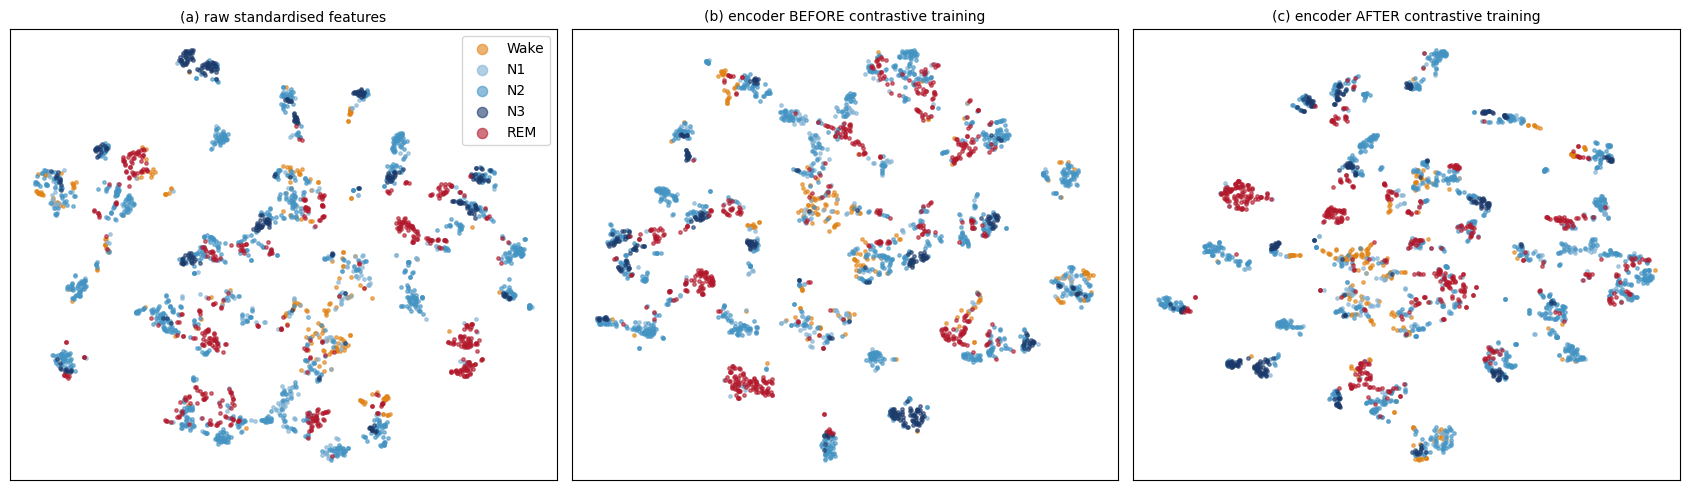

In [11]:
from sklearn.manifold import TSNE

rng = np.random.default_rng(SEED)
sub = rng.choice(len(X_val), size=min(2500, len(X_val)), replace=False)

def tsne2d(a):
    return TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(a)

panels = {
    "(a) raw standardised features":      X_val[sub],
    "(b) encoder BEFORE contrastive training": l2norm(get_embeddings(encoder_untrained, X_val_t))[sub],
    "(c) encoder AFTER contrastive training":  l2norm(get_embeddings(encoder, X_val_t))[sub],
}
colors = ["#e08214", "#80b1d3", "#4393c3", "#1b3a6b", "#b2182b"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, arr) in zip(axes, panels.items()):
    xy = tsne2d(arr)
    for c, name in enumerate(LABELS):
        m = y_val[sub] == c
        ax.scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.6, c=colors[c], label=name)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3, loc="best")
plt.tight_layout(); plt.show()

## 8. Stage 2 — classification head: linear probe, then fine-tuning

**(a) Linear probe.** Freeze the encoder, train *only* the linear head with class-weighted cross-entropy. This answers: *"how linearly separable are the stages in the learned representation?"* It is a clean measure of representation quality.

**(b) Fine-tuning.** Unfreeze everything and continue training with a **small learning rate for the encoder (1e-4)** and a larger one for the head (1e-3), so the encoder adapts without forgetting what contrastive learning gave it. Starting fine-tuning from the already-trained head ("linear-probe-then-fine-tune") is known to work better than starting from a random head.

Both use **early stopping on validation accuracy** (`SELECT_METRIC`, switchable to `"macro_f1"`): if it does not improve for 10 epochs we stop and restore the best weights. The test set plays no role here.

In [12]:
@torch.no_grad()
def predict(model, X_t, bs=2048):
    model.eval()
    logits = torch.cat([model(X_t[i:i + bs].to(device)).cpu() for i in range(0, len(X_t), bs)])
    return logits.argmax(1).numpy()

def metric_dict(y_true, y_pred):
    return {
        "accuracy":     accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "macro_f1":     f1_score(y_true, y_pred, average="macro", labels=list(range(N_CLASSES)), zero_division=0),
        "kappa":        cohen_kappa_score(y_true, y_pred),
    }

SELECT_METRIC = "accuracy"      # metric used on the VALIDATION subjects for early stopping / checkpoint choice

def set_encoder_trainable(model, flag):
    for p in model.encoder.parameters():
        p.requires_grad = flag

def train_classifier(model, optimizer, epochs, loader, freeze_encoder=False, patience=10, tag="", verbose=True):
    ce = nn.CrossEntropyLoss(weight=class_weights)
    hist = {"train_loss": [], "val_score": []}
    best_f1, best_state, best_ep, bad = -1.0, None, 0, 0
    for ep in range(1, epochs + 1):
        model.train()
        if freeze_encoder:
            model.encoder.eval()                               # keep BatchNorm/Dropout of the frozen encoder fixed
        total, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = ce(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(xb); n += len(xb)
        val_f1 = metric_dict(y_val, predict(model, X_val_t))[SELECT_METRIC]
        hist["train_loss"].append(total / n); hist["val_score"].append(val_f1)
        if val_f1 > best_f1:
            best_f1, best_state, best_ep, bad = val_f1, copy.deepcopy(model.state_dict()), ep, 0
        else:
            bad += 1
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"[{tag}] epoch {ep:3d} | train loss {hist['train_loss'][-1]:.4f} | val {SELECT_METRIC} {val_f1:.4f}")
        if bad >= patience:
            if verbose: print(f"[{tag}] early stop at epoch {ep} (best epoch {best_ep}, val {SELECT_METRIC} {best_f1:.4f})")
            break
    model.load_state_dict(best_state)
    hist["best_epoch"], hist["best_val_score"] = best_ep, best_f1
    return hist

# ---------- (a) linear probe: encoder frozen ----------
clf = SleepClassifier(encoder).to(device)
set_encoder_trainable(clf, False)
opt_probe = torch.optim.Adam(clf.head.parameters(), lr=1e-2, weight_decay=1e-4)
probe_hist = train_classifier(clf, opt_probe, epochs=40, loader=train_loader, freeze_encoder=True, tag="linear probe")
clf_probe = copy.deepcopy(clf)                                 # snapshot for the final comparison

[linear probe] epoch   1 | train loss 1.1343 | val accuracy 0.5548
[linear probe] epoch   5 | train loss 0.9677 | val accuracy 0.5608
[linear probe] epoch  10 | train loss 0.9457 | val accuracy 0.5697
[linear probe] epoch  15 | train loss 0.9387 | val accuracy 0.5637
[linear probe] epoch  20 | train loss 0.9324 | val accuracy 0.5574
[linear probe] early stop at epoch 20 (best epoch 10, val accuracy 0.5697)


[fine-tune] epoch   1 | train loss 1.0112 | val accuracy 0.5589
[fine-tune] epoch   5 | train loss 0.9802 | val accuracy 0.5570
[fine-tune] epoch  10 | train loss 0.9531 | val accuracy 0.5579
[fine-tune] early stop at epoch 13 (best epoch 3, val accuracy 0.5591)


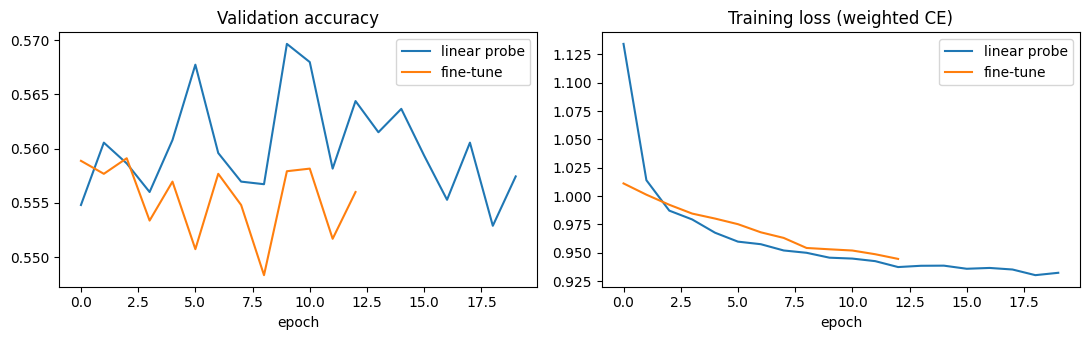

In [13]:
# ---------- (b) fine-tuning: everything trainable ----------
set_encoder_trainable(clf, True)
opt_ft = torch.optim.Adam([
    {"params": clf.encoder.parameters(), "lr": 1e-4},          # gentle updates to the pre-trained encoder
    {"params": clf.head.parameters(),    "lr": 1e-3},
], weight_decay=1e-4)
ft_hist = train_classifier(clf, opt_ft, epochs=60, loader=train_loader, patience=10, tag="fine-tune")
clf_finetuned = clf

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(probe_hist["val_score"], label="linear probe"); ax[0].plot(ft_hist["val_score"], label="fine-tune")
ax[0].set(title=f"Validation {SELECT_METRIC}", xlabel="epoch"); ax[0].legend()
ax[1].plot(probe_hist["train_loss"], label="linear probe"); ax[1].plot(ft_hist["train_loss"], label="fine-tune")
ax[1].set(title="Training loss (weighted CE)", xlabel="epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Supervised MLP baseline

Same `encoder + head` architecture, **random initialisation, trained end-to-end with the same weighted cross-entropy**, same data, same early-stopping rule on validation accuracy. We give it a generous budget (up to 100 epochs, patience 15) — the contrastive pipeline used up to 60 + 40 epochs plus pre-training, so the baseline is not short-changed.

The only difference is the **training recipe**: *contrastive pre-training → classifier* vs. *classifier from scratch*.

In [14]:
set_seed(SEED)
baseline = SleepClassifier(make_encoder()).to(device)
opt_base = torch.optim.Adam(baseline.parameters(), lr=1e-3, weight_decay=1e-4)
base_hist = train_classifier(baseline, opt_base, epochs=100, loader=make_train_loader(SEED), patience=15, tag="baseline MLP")

[baseline MLP] epoch   1 | train loss 1.3124 | val accuracy 0.5318
[baseline MLP] epoch   5 | train loss 1.0015 | val accuracy 0.5742
[baseline MLP] epoch  10 | train loss 0.9305 | val accuracy 0.5625
[baseline MLP] epoch  15 | train loss 0.8768 | val accuracy 0.5436
[baseline MLP] epoch  20 | train loss 0.8387 | val accuracy 0.5512
[baseline MLP] early stop at epoch 20 (best epoch 5, val accuracy 0.5742)


## 10. Temporal smoothing — the biggest single accuracy gain

A sleep stage lasts for many minutes, but a per-epoch classifier decides every 30-second epoch **independently**, so its predictions "flicker" (N2, N2, REM, N2, N2 …). Averaging the **predicted probabilities over neighbouring epochs of the same subject** removes most of that flicker.

* It needs **no extra training and no labels** — only the model's own probabilities, and only epochs of the *same* person (we group by subject and sort by time, so nothing leaks between people).
* The window length (1 = no smoothing, up to 31 epochs ≈ 15 min) is **chosen on the validation subjects**, never on the test subjects.
* ⚠️ It looks at epochs *before and after* the current one, so it is an **offline** analysis step (like scoring a night after waking up), not a real-time one. State this in the presentation.

We apply the identical post-processing to the contrastive models **and** to the baseline, so the comparison stays fair.

In [15]:
from scipy.ndimage import uniform_filter1d

WINDOWS = [1, 3, 5, 7, 11, 15, 21, 31]                 # in epochs (1 = no smoothing)
subj_val,  t_val  = val_df["subject"].to_numpy(),  val_df["time"].to_numpy()
subj_test, t_test = test_df["subject"].to_numpy(), test_df["time"].to_numpy()

@torch.no_grad()
def predict_proba(model, X_t, bs=2048):
    model.eval()
    logits = torch.cat([model(X_t[i:i + bs].to(device)).cpu() for i in range(0, len(X_t), bs)])
    return torch.softmax(logits, dim=1).numpy()

def smooth_probs(P, subjects, times, win):
    """Moving average of class probabilities over `win` epochs, separately for each subject, in time order."""
    if win <= 1:
        return P
    out = P.copy()
    for s in np.unique(subjects):
        idx = np.where(subjects == s)[0]
        idx = idx[np.argsort(times[idx], kind="stable")]               # chronological order within the subject
        out[idx] = uniform_filter1d(P[idx], size=win, axis=0, mode="nearest")
    return out

def evaluate_smoothed(model):
    """Pick the smoothing window on VALIDATION accuracy, then apply it to validation and test predictions."""
    Pv, Pt = predict_proba(model, X_val_t), predict_proba(model, X_test_t)
    val_acc = {w: accuracy_score(y_val, smooth_probs(Pv, subj_val, t_val, w).argmax(1)) for w in WINDOWS}
    best_w = max(val_acc, key=val_acc.get)
    return {"window": best_w, "val_acc_by_window": val_acc,
            "val_raw_pred":  Pv.argmax(1), "val_pred":  smooth_probs(Pv, subj_val,  t_val,  best_w).argmax(1),
            "test_raw_pred": Pt.argmax(1), "test_pred": smooth_probs(Pt, subj_test, t_test, best_w).argmax(1)}

## 11. Validation-set comparison (raw vs. smoothed)

These numbers come from the 5 **validation subjects** (used to choose checkpoints and smoothing windows, so slightly optimistic — the honest numbers are in section 12).

In [16]:
models = {
    "Contrastive + linear probe": clf_probe,
    "Contrastive + fine-tune":    clf_finetuned,
    "Supervised MLP baseline":    baseline,
}
smooth_res = {name: evaluate_smoothed(m) for name, m in models.items()}

rows = {}
for name, r in smooth_res.items():
    rows[f"{name} (raw)"]                      = metric_dict(y_val, r["val_raw_pred"])
    rows[f"{name} (smoothed, win={r['window']})"] = metric_dict(y_val, r["val_pred"])
val_table = pd.DataFrame(rows).T
display(val_table.round(4))

pd.DataFrame({n: r["val_acc_by_window"] for n, r in smooth_res.items()}).round(4).rename_axis("window (epochs)")

,accuracy,balanced_acc,macro_f1,kappa
Contrastive + linear probe (raw),0.5697,0.4734,0.4732,0.3634
"Contrastive + linear probe (smoothed, win=21)",0.5847,0.4532,0.4487,0.3660
Contrastive + fine-tune (raw),0.5591,0.4783,0.4798,0.3562
"Contrastive + fine-tune (smoothed, win=11)",0.5692,0.4655,0.4592,0.3584
Supervised MLP baseline (raw),0.5742,0.4837,0.4813,0.3773
"Supervised MLP baseline (smoothed, win=7)",0.5850,0.4773,0.4785,0.3838


,Contrastive + linear probe,Contrastive + fine-tune,Supervised MLP baseline
window (epochs),,,
1,0.5697,0.5591,0.5742
3,0.5732,0.5620,0.5833
5,0.5761,0.5632,0.5819
7,0.5775,0.5665,0.5850
11,0.5799,0.5692,0.5771
15,0.5835,0.5685,0.5740
21,0.5847,0.5594,0.5740
31,0.5831,0.5527,0.5768


## 12. Final evaluation on the held-out TEST subjects

This is the number we report. The 7 test subjects were never used for fitting, scaling, class weights, early stopping, checkpoint selection or choosing the smoothing window. We report:

* **Accuracy** – how often we are right (N2 is ~46 % of test epochs, so a model that always says "N2" already gets that).
* **Balanced accuracy** – average recall per class.
* **Macro-F1** – average F1 per class.
* **Cohen's kappa** – agreement beyond chance; the standard metric in sleep-staging papers.

The **headline results are the smoothed predictions**; the raw (per-epoch) results are shown alongside for transparency.

In [17]:
test_preds     = {name: r["test_pred"]     for name, r in smooth_res.items()}       # headline: smoothed
test_preds_raw = {name: r["test_raw_pred"] for name, r in smooth_res.items()}

test_table = pd.DataFrame({name: metric_dict(y_test, p) for name, p in test_preds.items()}).T
raw_table  = pd.DataFrame({name: metric_dict(y_test, p) for name, p in test_preds_raw.items()}).T
print("TEST-set results, per-epoch predictions (raw):")
display(raw_table.round(4))
print("\nTEST-set results, with temporal smoothing (HEADLINE) - windows chosen on validation:",
      {n: r["window"] for n, r in smooth_res.items()})
display(test_table.round(4))

per_class_f1 = pd.DataFrame({
    name: f1_score(y_test, p, average=None, labels=list(range(N_CLASSES)), zero_division=0)
    for name, p in test_preds.items()
}, index=LABELS).T
print("\nPer-class F1 on test (smoothed):")
display(per_class_f1.round(3))

print("\nDetailed report - Contrastive + fine-tune (smoothed):")
print(classification_report(y_test, test_preds["Contrastive + fine-tune"], labels=list(range(N_CLASSES)),
                            target_names=LABELS, digits=3, zero_division=0))

TEST-set results, per-epoch predictions (raw):


,accuracy,balanced_acc,macro_f1,kappa
Contrastive + linear probe,0.5510,0.4279,0.4254,0.3354
Contrastive + fine-tune,0.5387,0.4301,0.4318,0.3280
Supervised MLP baseline,0.5509,0.4539,0.4536,0.3541



TEST-set results, with temporal smoothing (HEADLINE) - windows chosen on validation: {'Contrastive + linear probe': 21, 'Contrastive + fine-tune': 11, 'Supervised MLP baseline': 7}


,accuracy,balanced_acc,macro_f1,kappa
Contrastive + linear probe,0.5976,0.4404,0.4366,0.3827
Contrastive + fine-tune,0.5718,0.4405,0.4386,0.3628
Supervised MLP baseline,0.5752,0.4613,0.4624,0.3798



Per-class F1 on test (smoothed):


,Wake,N1,N2,N3,REM
Contrastive + linear probe,0.494,0.000,0.664,0.336,0.689
Contrastive + fine-tune,0.467,0.028,0.637,0.420,0.640
Supervised MLP baseline,0.441,0.111,0.637,0.489,0.634



Detailed report - Contrastive + fine-tune (smoothed):
              precision    recall  f1-score   support

        Wake      0.563     0.399     0.467       562
          N1      0.188     0.015     0.028       392
          N2      0.601     0.678     0.637      2768
          N3      0.491     0.368     0.420       984
         REM      0.562     0.743     0.640      1301

    accuracy                          0.572      6007
   macro avg      0.481     0.440     0.439      6007
weighted avg      0.544     0.572     0.547      6007



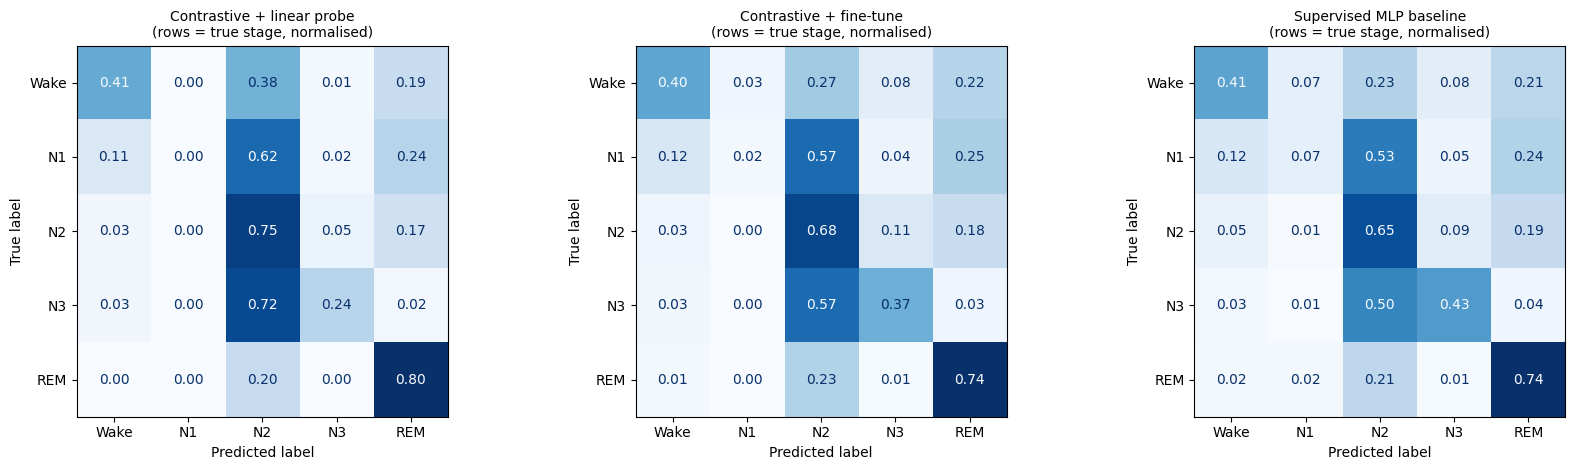

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, p) in zip(axes, test_preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=LABELS, normalize="true",
                                            values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}\n(rows = true stage, normalised)", fontsize=10)
plt.tight_layout(); plt.show()

### Per-subject performance

A single pooled number can hide that some people are much harder to stage than others. With only 7 test subjects the spread matters — report it alongside the average.

,epochs,Contrastive + fine-tune,Supervised MLP baseline
subject,,,
3997827,958,0.477,0.441
4018081,498,0.380,0.429
5498603,743,0.421,0.451
6220552,955,0.365,0.401
8258170,972,0.488,0.495
8692923,936,0.446,0.462
9618981,945,0.356,0.435


Mean over subjects:
 Contrastive + fine-tune    0.4191
Supervised MLP baseline    0.4449


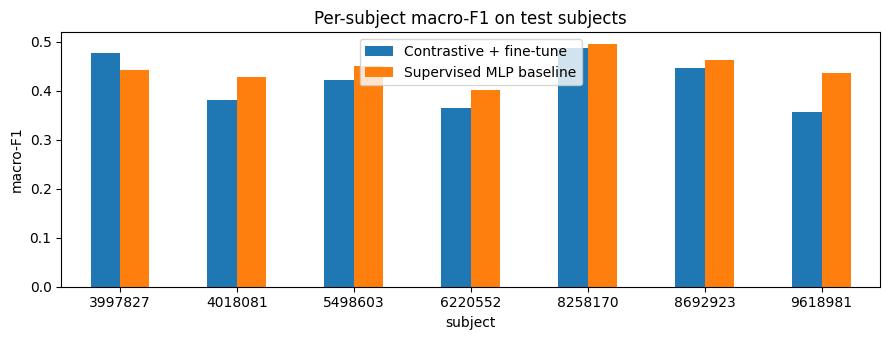

In [19]:
subj_test = test_df["subject"].to_numpy()
rows = []
for s in sorted(S_test):
    m = subj_test == s
    row = {"subject": s, "epochs": int(m.sum())}
    for name in ["Contrastive + fine-tune", "Supervised MLP baseline"]:
        p = test_preds[name]
        row[name] = f1_score(y_test[m], p[m], average="macro", labels=np.unique(y_test[m]), zero_division=0)
    rows.append(row)
per_subject = pd.DataFrame(rows).set_index("subject")
display(per_subject.round(3))
print("Mean over subjects:\n", per_subject[["Contrastive + fine-tune", "Supervised MLP baseline"]].mean().round(4).to_string())

per_subject[["Contrastive + fine-tune", "Supervised MLP baseline"]].plot.bar(figsize=(9, 3.5))
plt.ylabel("macro-F1"); plt.title("Per-subject macro-F1 on test subjects"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 13. Robustness: is the difference real or just a lucky seed?

Neural-network results move a little with the random initialisation. With a single run we cannot say whether a +0.01 difference means anything. Here we repeat the **whole pipeline** (pre-train → probe → fine-tune, and baseline, including the smoothing-window choice) with 4 more seeds. The subject split stays fixed. Nothing is chosen using the test set — it is only reported; all numbers here are the smoothed ones.

Set `RUN_SEED_SWEEP = False` if you want to skip this (it takes a few minutes on GPU).

In [20]:
RUN_SEED_SWEEP = True
SWEEP_SEEDS = [1, 2, 3, 4]

def run_one_seed(seed):
    set_seed(seed)
    loader = make_train_loader(seed)
    enc, proj = make_encoder(), ProjectionHead().to(device)
    pretrain_supcon(enc, proj, loader, verbose=False)
    m = SleepClassifier(enc).to(device)
    set_encoder_trainable(m, False)
    train_classifier(m, torch.optim.Adam(m.head.parameters(), lr=1e-2, weight_decay=1e-4),
                     40, loader, freeze_encoder=True, verbose=False)
    probe = copy.deepcopy(m)
    set_encoder_trainable(m, True)
    train_classifier(m, torch.optim.Adam([{"params": m.encoder.parameters(), "lr": 1e-4},
                                          {"params": m.head.parameters(), "lr": 1e-3}], weight_decay=1e-4),
                     60, loader, patience=10, verbose=False)
    b = SleepClassifier(make_encoder()).to(device)
    train_classifier(b, torch.optim.Adam(b.parameters(), lr=1e-3, weight_decay=1e-4), 100, loader, patience=15, verbose=False)
    return {name: metric_dict(y_test, evaluate_smoothed(mm)["test_pred"])        # smoothed, window chosen on validation
            for name, mm in [("Contrastive + linear probe", probe), ("Contrastive + fine-tune", m), ("Supervised MLP baseline", b)]}

sweep = {SEED: {name: metric_dict(y_test, p) for name, p in test_preds.items()}}   # main run (smoothed)
if RUN_SEED_SWEEP:
    for sd in SWEEP_SEEDS:
        t0 = time.time(); sweep[sd] = run_one_seed(sd); print(f"seed {sd} done ({time.time() - t0:.0f}s)")

long = pd.DataFrame([{"seed": sd, "model": name, **mt} for sd, d in sweep.items() for name, mt in d.items()])
summary = long.groupby("model")[["accuracy", "balanced_acc", "macro_f1", "kappa"]].agg(["mean", "std"]).round(4)
print(f"\nTest metrics over {len(sweep)} seeds (mean, std):")
display(summary)
display(long.pivot(index="seed", columns="model", values="macro_f1").round(4))

seed 1 done (37s)
seed 2 done (38s)
seed 3 done (39s)
seed 4 done (36s)

Test metrics over 5 seeds (mean, std):


accuracy         balanced_acc         macro_f1  \
                               mean     std         mean     std     mean   
model                                                                       
Contrastive + fine-tune      0.5836  0.0171       0.4450  0.0068   0.4455   
Contrastive + linear probe   0.5825  0.0125       0.4383  0.0049   0.4365   
Supervised MLP baseline      0.5900  0.0117       0.4559  0.0101   0.4538   

                                     kappa          
                               std    mean     std  
model                                               
Contrastive + fine-tune     0.0104  0.3752  0.0199  
Contrastive + linear probe  0.0056  0.3679  0.0158  
Supervised MLP baseline     0.0135  0.3905  0.0105

model,Contrastive + fine-tune,Contrastive + linear probe,Supervised MLP baseline
seed,,,
1,0.4436,0.4280,0.4411
2,0.4637,0.4419,0.4634
3,0.4424,0.4410,0.4371
4,0.4393,0.4349,0.4650
42,0.4386,0.4366,0.4624


## 14. Save outputs & verify the frozen data was not modified

Everything is saved under `ColabData/contrastive_outputs/` — **not** in the `frozen/` folder.

In [21]:
torch.save(clf_finetuned.state_dict(), OUT_DIR / "contrastive_finetuned.pt")
torch.save(clf_probe.state_dict(),     OUT_DIR / "contrastive_linear_probe.pt")
torch.save(baseline.state_dict(),      OUT_DIR / "baseline_mlp.pt")
test_table.to_csv(OUT_DIR / "test_metrics_main_run_smoothed.csv")
raw_table.to_csv(OUT_DIR / "test_metrics_main_run_raw.csv")
long.to_csv(OUT_DIR / "test_metrics_all_seeds.csv", index=False)
with open(OUT_DIR / "run_config.json", "w") as fh:
    json.dump({
        "seed": SEED, "features": feature_cols, "labels": LABELS,
        "val_subjects": sorted(S_val), "test_subjects": sorted(S_test),
        "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
        "pretrain_epochs": PRETRAIN_EPOCHS, "temperature": TEMPERATURE, "noise_std": NOISE_STD,
        "batch_size": BATCH_SIZE, "embedding_dim": REP_DIM,
        "class_weight_power": CLASS_WEIGHT_POWER, "select_metric": SELECT_METRIC,
        "smoothing_windows": {n: r["window"] for n, r in smooth_res.items()},
    }, fh, indent=2)
print("Saved to", OUT_DIR, "->", sorted(p.name for p in OUT_DIR.iterdir()))

# ---- integrity check of the frozen dataset ----
after = {f: sha256(FROZEN_DIR / f) for f in REQUIRED}
assert after == FROZEN_HASHES, "Frozen data changed!"
print("Frozen dataset verified: SHA-256 identical to the fingerprint taken at the start.")

Saved to /content/drive/MyDrive/Colab Notebooks/ColabData/contrastive_outputs -> ['baseline_mlp.pt', 'contrastive_finetuned.pt', 'contrastive_linear_probe.pt', 'run_config.json', 'test_metrics_all_seeds.csv', 'test_metrics_main_run_raw.csv', 'test_metrics_main_run_smoothed.csv']
Frozen dataset verified: SHA-256 identical to the fingerprint taken at the start.
